In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Grid dimensions
GRID_ROWS = 4
GRID_COLS = 4

# Start, Goal and Obstacle positions
START = (3, 0)
GOAL = (0, 3)
WALL = (1, 1)

# Rewards
REWARD_GOAL = 10.0
REWARD_WALL = -1.0
REWARD_DEFAULT = 0.0

# Q-Learning parameters
ALPHA = 0.5
GAMMA = 0.9
EPISODES = 2000

# Actions: Up, Down, Left, Right
ACTIONS = ['Up', 'Down', 'Left', 'Right']

ACTION_MOVES = {
    'Up': (-1, 0),
    'Down': (1, 0),
    'Left': (0, -1),
    'Right': (0, 1)
}

print("Grid World Environment Initialized Successfully!")
print("Grid Size:", GRID_ROWS, "x", GRID_COLS)
print("Start:", START)
print("Goal:", GOAL)
print("Obstacle:", WALL)

Grid World Environment Initialized Successfully!
Grid Size: 4 x 4
Start: (3, 0)
Goal: (0, 3)
Obstacle: (1, 1)


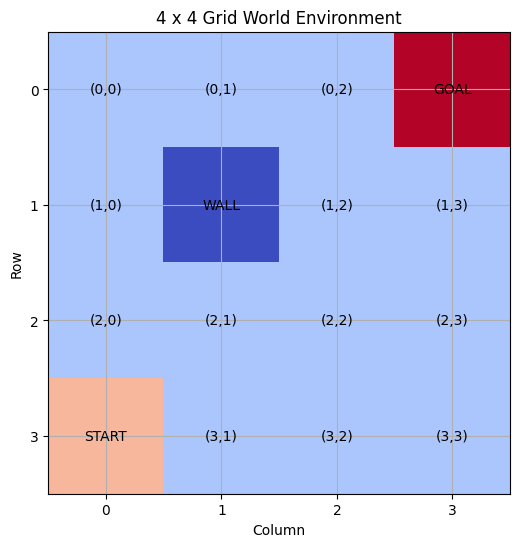

In [ ]:
grid = np.zeros((GRID_ROWS, GRID_COLS))

grid[START] = 1
grid[GOAL] = 2
grid[WALL] = -1

plt.figure(figsize=(6, 6))
plt.imshow(grid, cmap="coolwarm", vmin=-1, vmax=2)

for r in range(GRID_ROWS):
    for c in range(GRID_COLS):
        if (r, c) == START:
            label = "START"
        elif (r, c) == GOAL:
            label = "GOAL"
        elif (r, c) == WALL:
            label = "WALL"
        else:
            label = f"({r},{c})"

        plt.text(c, r, label, ha="center", va="center",
                 color="black", fontsize=10)

plt.xticks(range(GRID_COLS))
plt.yticks(range(GRID_ROWS))
plt.title("4 x 4 Grid World Environment")
plt.xlabel("Column")
plt.ylabel("Row")
plt.grid(True)
plt.show()

In [ ]:
def step(state, action_idx):

    # If the agent is already at the goal
    if state == GOAL:
        return state, 0, True

    action_name = ACTIONS[action_idx]

    # Get movement direction
    dr, dc = ACTION_MOVES[action_name]

    next_r = state[0] + dr
    next_c = state[1] + dc

    # Check grid boundaries
    if (next_r < 0 or next_r >= GRID_ROWS or
            next_c < 0 or next_c >= GRID_COLS):
        next_state = state
    else:
        next_state = (next_r, next_c)

    # Assign reward
    if next_state == WALL:
        reward = REWARD_WALL
        is_terminal = False

    elif next_state == GOAL:
        reward = REWARD_GOAL
        is_terminal = True

    else:
        reward = REWARD_DEFAULT
        is_terminal = False

    return next_state, reward, is_terminal


# Test the function
print("Testing environment:")

next_state, reward, done = step(START, 0)

print("Current State:", START)
print("Action:", ACTIONS[0])
print("Next State:", next_state)
print("Reward:", reward)
print("Terminal:", done)

Testing environment:
Current State: (3, 0)
Action: Up
Next State: (2, 0)
Reward: 0.0
Terminal: False


In [ ]:
def run_q_learning():

    # Initialize Q-table with zeros
    q_table = np.zeros(
        (GRID_ROWS, GRID_COLS, len(ACTIONS))
    )

    # Store total reward from each episode
    episode_rewards = []

    for episode in range(EPISODES):

        state = START
        is_terminal = False
        total_reward = 0
        steps = 0

        # Exploration decreases over time
        epsilon = max(0.1, 1.0 - episode / 1000)

        while not is_terminal and steps < 100:

            # Epsilon-greedy action selection
            if np.random.rand() < epsilon:
                action_idx = np.random.choice(len(ACTIONS))
            else:
                action_idx = np.argmax(
                    q_table[state[0], state[1]]
                )

            # Perform the action
            next_state, reward, is_terminal = step(
                state, action_idx
            )

            # Find maximum future Q-value
            if is_terminal:
                max_next_q = 0.0
            else:
                max_next_q = np.max(
                    q_table[next_state[0], next_state[1]]
                )

            # Calculate target and temporal difference error
            td_target = reward + GAMMA * max_next_q

            td_error = (
                td_target -
                q_table[state[0], state[1], action_idx]
            )

            # Update Q-value
            q_table[state[0], state[1], action_idx] += (
                ALPHA * td_error
            )

            state = next_state
            total_reward += reward
            steps += 1

        episode_rewards.append(total_reward)

    return q_table, episode_rewards


# Train the agent
q_table, episode_rewards = run_q_learning()

print("Q-Learning Training Completed!")
print("Total Episodes:", EPISODES)
print("Q-table Shape:", q_table.shape)

Q-Learning Training Completed!
Total Episodes: 2000
Q-table Shape: (4, 4, 4)


In [ ]:
rows = []

for r in range(GRID_ROWS):
    for c in range(GRID_COLS):

        state = (r, c)

        if state == GOAL:
            rows.append({
                "State": str(state) + " [Goal]",
                "Up": "-",
                "Down": "-",
                "Left": "-",
                "Right": "-",
                "Optimal Action": "Terminal"
            })

        elif state == WALL:
            rows.append({
                "State": str(state) + " [Wall]",
                "Up": "-",
                "Down": "-",
                "Left": "-",
                "Right": "-",
                "Optimal Action": "Obstacle"
            })

        else:
            q_vals = q_table[r, c]
            best_action = ACTIONS[np.argmax(q_vals)]

            rows.append({
                "State": str(state),
                "Up": round(q_vals[0], 4),
                "Down": round(q_vals[1], 4),
                "Left": round(q_vals[2], 4),
                "Right": round(q_vals[3], 4),
                "Optimal Action": best_action
            })

df_qtable = pd.DataFrame(rows)

print("CONVERGED Q-TABLE")
display(df_qtable)

CONVERGED Q-TABLE


,State,Up,Down,Left,Right,Optimal Action
0,"(0, 0)",7.29,6.561,7.29,8.1,Right
1,"(0, 1)",8.1,6.29,7.29,9.0,Right
2,"(0, 2)",9.0,8.1,8.1,10.0,Right
3,"(0, 3) [Goal]",-,-,-,-,Terminal
4,"(1, 0)",7.29,5.9049,6.561,6.29,Up
5,"(1, 1) [Wall]",-,-,-,-,Obstacle
6,"(1, 2)",9.0,7.29,6.29,9.0,Up
7,"(1, 3)",10.0,8.1,8.1,9.0,Up
8,"(2, 0)",6.561,5.3144,5.9049,6.561,Up
9,"(2, 1)",6.29,5.9049,5.9049,7.29,Right


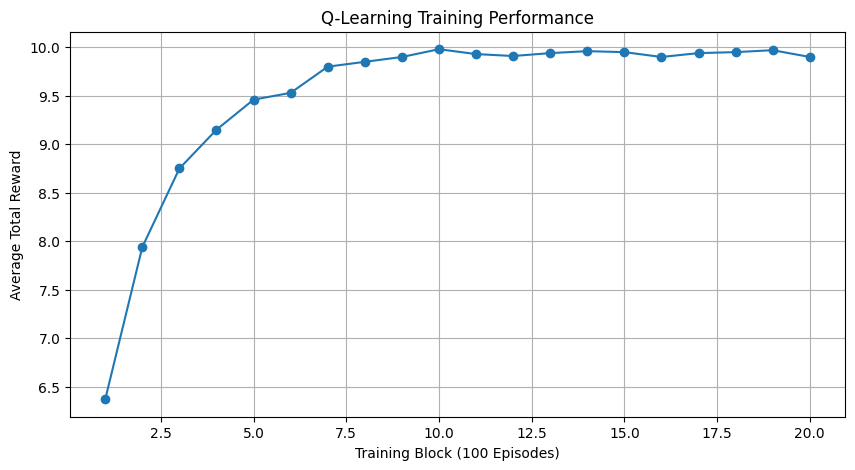

In [ ]:
# Calculate average reward over groups of 100 episodes
window = 100

average_rewards = [
    np.mean(episode_rewards[i:i + window])
    for i in range(0, len(episode_rewards), window)
]

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(average_rewards) + 1),
    average_rewards,
    marker="o"
)

plt.title("Q-Learning Training Performance")
plt.xlabel("Training Block (100 Episodes)")
plt.ylabel("Average Total Reward")
plt.grid(True)

plt.show()

In [ ]:
def get_optimal_path(q_table):

    state = START
    path = [state]
    max_steps = 30

    for _ in range(max_steps):

        if state == GOAL:
            break

        # Choose the action with the highest Q-value
        action_idx = np.argmax(q_table[state[0], state[1]])

        next_state, reward, done = step(state, action_idx)

        # Stop if the policy gets stuck
        if next_state == state:
            break

        state = next_state
        path.append(state)

        if done:
            break

    return path


optimal_path = get_optimal_path(q_table)

print("Optimal Path:")
print(" -> ".join(str(state) for state in optimal_path))

if optimal_path[-1] == GOAL:
    print("Goal reached successfully!")
else:
    print("Goal not reached. Try running the training cell again.")

Optimal Path:
(3, 0) -> (2, 0) -> (1, 0) -> (0, 0) -> (0, 1) -> (0, 2) -> (0, 3)
Goal reached successfully!


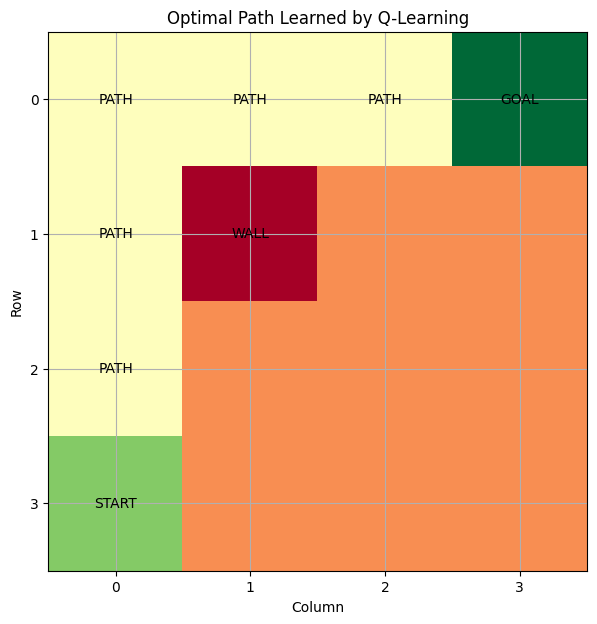

In [ ]:
path_grid = np.zeros((GRID_ROWS, GRID_COLS))

for r, c in optimal_path:
    path_grid[r, c] = 1

# Mark special cells
path_grid[WALL] = -1
path_grid[START] = 2
path_grid[GOAL] = 3

plt.figure(figsize=(7, 7))
plt.imshow(path_grid, cmap="RdYlGn", vmin=-1, vmax=3)

for r in range(GRID_ROWS):
    for c in range(GRID_COLS):

        if (r, c) == START:
            label = "START"
        elif (r, c) == GOAL:
            label = "GOAL"
        elif (r, c) == WALL:
            label = "WALL"
        elif (r, c) in optimal_path:
            label = "PATH"
        else:
            label = ""

        plt.text(c, r, label, ha="center", va="center",
                 color="black", fontsize=10)

plt.xticks(range(GRID_COLS))
plt.yticks(range(GRID_ROWS))
plt.title("Optimal Path Learned by Q-Learning")
plt.xlabel("Column")
plt.ylabel("Row")
plt.grid(True)
plt.show()